# Tutorial 1, simplified: A. Relative noise, Fisher-matrix uncertainty, fast optimiser

Parameter estimation and uncertainty for the fed-batch yeast model of tutorial 1 (`model.py`, model
`MI`, 4 parameters: $\mu_{max}$, $K_s$, $Y_{xs}$, $m$), written as a plain MIDDoE script:

1. the parameters, then the dictionaries `system`, `models`, `insilicos`, `iden_opt`;
2. three rounds, each: run one experiment in silico (`expera`), estimate (`parmest`), quantify the
   uncertainty (`uncert`), store the round (`save_rounds`);
3. the final report (`run_postprocessing`).

What this notebook (variant **A**) uses:

| | |
|---|---|
| noise of the data | relative: σ = 8 % of the true value (`insilicos['errt'] = 'rel'`) |
| optimiser | `'SLSQP'`, one start: the fewest model runs |
| uncertainty | `'M'`: Fisher information matrix from the sensitivities (fast, linearised) |
| extras | none |

The variants A, B, B2, C and D use the same model and the same experiments; compare their reports. The full
tutorial (`../../01_estimation_and_uncertainty/tutorial.ipynb`) explains every step in detail.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zuhairblr/middoe/blob/main/tests/tutorials/01_simple/a_relative_fisher_fast/runner.ipynb)

**On Google Colab?** Run the next cell first: it installs MIDDoE and downloads `model.py` into the session
(on your own PC it does nothing).

In [ ]:
# Google Colab only: install MIDDoE and fetch model.py; does nothing elsewhere
import sys
if 'google.colab' in sys.modules:
    import subprocess, urllib.request
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'git+https://github.com/zuhairblr/middoe.git'], check=True)
    urllib.request.urlretrieve('https://raw.githubusercontent.com/zuhairblr/middoe/main/tests/tutorials/01_simple/a_relative_fisher_fast/model.py', 'model.py')

In [1]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd

from middoe.krnl_expera import expera            # in-silico experiment -> data.xlsx (+ data preview)
from middoe.iden_parmest import parmest          # parameter estimation
from middoe.iden_uncert import uncert            # uncertainty: covariance, CI, t-values
from middoe.sc_estima import estima              # estimability analysis (ranking, subset selection)
from middoe.log_utils import save_rounds, save_to_jac, load_from_jac   # round storage
from middoe.iden_utils import run_postprocessing # final report

HERE = Path.cwd()
# Start clean: expera() ADDS sheets to an existing data.xlsx.
for old in ['data.xlsx', 'data_plots', 'modelling', 'confidence', 'post_processing', 'estimability',
            'meshindep_plots', 'iden_results.jac']:
    p = HERE / old
    shutil.rmtree(p) if p.is_dir() else p.unlink(missing_ok=True)
np.random.seed(0)                                # same noise at every run

NAMES = ['mu_max', 'Ks', 'Yxs', 'm']


def show_round(resultun, model='MI'):
    """Estimates, 95 % CI and t-test of one round, next to the true values."""
    r = resultun[model]
    act = np.asarray(r['optimization_result']['activeparams'], bool)   # parameters estimated this round
    ci = np.full(len(NAMES), np.nan); ci[act] = r['CI']
    tv = np.full(len(NAMES), np.nan); tv[act] = r['t_values']
    return pd.DataFrame({'estimate': r['estimations'], '± 95 % CI': ci, 't-value': tv,
                         'true': theta, 'estimated': act}, index=NAMES).round(4)

In [2]:
# ---------------- parameters ----------------
theta      = [0.25, 0.25, 0.88, 0.09]     # TRUE values: mu_max [1/h], Ks [g/L], Yxs [g/g], m [1/h].
                                          #   Only the virtual lab (insilicos) knows them.
theta_n    = [0.30, 0.30, 1.056, 0.108]   # starting guess for the estimation (here 1.2 x true)
theta_mins = [0.125, 0.125, 0.44, 0.045]  # lower bounds (physical units)
theta_maxs = [0.375, 0.375, 1.32, 0.135]  # upper bounds

In [3]:
system = {
    't_s': [0, 40],          # [start, end] of every experiment (h)
    't_r': 0.16,             # time step of the simulation grid; sampling times and input profiles lie on it
    't_d': 0,                # dead time at start and end (only used when designing experiments)

    'tvi': {                 # time-variant inputs u(t); keys = names the model receives in tvi[...]
        'u1': {'min': 0.05, 'max': 0.2,    # dilution rate [1/h]: allowed range
               'cvp': 'CPF',               # profile in designed experiments: 'CPF' steps, 'LPF' ramps,
                                           #   'no_CVP' constant. In-silico preliminary runs are constant.
               'stps': 5,                  # number of levels of a designed profile
               'const': 'rel',             # 'rel' free, 'inc' only increasing, 'dec' only decreasing
               'offl': 0.01, 'offt': 0.5},  # minimum level change / time between switches (designs only)
        'u2': {'min': 5, 'max': 35, 'cvp': 'LPF', 'stps': 5, 'const': 'rel', 'offl': 1, 'offt': 0.5},
    },
    'tii': {                 # time-invariant inputs: one value per experiment
        'y10': {'min': 1, 'max': 5.5},    # initial biomass [g/L]
    },
    'tvo': {                 # time-variant outputs; keys = names the model returns
        'y1': {'meas': True,  # measured (False: computed but not used in the fit)
               'unc': 0.08,     # measurement std. dev., relative: 8 % of the value (insilicos['errt'] below)
               'init': 0,     # initial value passed to the model (this model sets its own)
               'sp': 10,      # samples per experiment
               'samp_s': 1,   # sampling group: same number = sampled at the same times
               'samp_f': [],  # sampling times forced into designed experiments
               'offt': 0.5},  # minimum time between samples (designs)
        'y2': {'meas': True, 'unc': 0.08, 'init': 0.01, 'sp': 10, 'samp_s': 1, 'samp_f': [], 'offt': 0.5},
    },
    'tio': {},              # time-invariant outputs (none here)
}

In [4]:
models = {
    'can_m': ['MI'],                    # candidate models (several for discrimination)
    'krt': {'MI': 'pys'},               # 'pys' = Python file with solve_model(t, y0, tii, tvi, theta);
                                        #   'pym' = built-in model of middoe.krnl_models; 'gpr' = gPROMS
    'src': {'MI': str(HERE / 'model.py')},   # path of the model file
    'creds': {'MI': ''},                # gPROMS credentials ('' for Python models)
    'theta': {'MI': list(theta_n)},     # starting guess (uncert() overwrites it with the estimate)
    't_l': {'MI': theta_mins},          # lower bounds
    't_u': {'MI': theta_maxs},          # upper bounds
    'mutation': {'MI': [True] * 4},     # True = estimate, False = keep fixed at 'theta'
    'theta_names': {'MI': NAMES},       # optional: names on the plots (default theta_1 ...)
}

In [5]:
insilicos = {                         # the virtual lab that replaces real experiments
    'tr_m': 'MI',                       # model playing the real process
    'theta': theta,                     # its true parameters
    'errt': 'rel',                     # noise: 'rel' = sigma = unc * |true value| (at least sigma_floor)
    # 'sigma_floor': 1e-6,              # smallest sigma with 'rel' (e.g. a detection limit)
    'plt': True,                        # small figure of the new data and its noise after every expera()
                                        #   (also saved in data_plots/); False = no figure
    'prels': {                          # preliminary experiments: constant inputs, keyed by experiment number
        '1': {'u1': 0.05, 'u2': 30, 'y10': 5.5},
        '2': {'u1': 0.10, 'u2': 30, 'y10': 5.5},
        '3': {'u1': 0.15, 'u2': 20, 'y10': 2.0},
    },
}

In [6]:
iden_opt = {
    # ---- estimation (parmest) ----
    'meth': 'SLSQP',       # optimiser: 'SLSQP' local gradient-based (fewest model runs)
                         #   others: 'SLSQP', 'LMBFGS', 'TC' (trust region), 'NMS' (Nelder-Mead, no gradients),
                         #   'BFGS' (ignores bounds), 'DE' (global differential evolution, slow)
    'ms': False,          # multi-start: False = one start from models['theta']; True = also random starts in parallel
    'ob': 'WLS',          # objective: 'WLS' weighted least squares sum((r/sigma)^2), sigma from the MES_E column
                         #   others: 'WLS', 'MLE', 'LS' (ignores sigma), 'Chi' (relative least squares)
    'maxit': 500,        # maximum iterations
    'tol': 1e-8,         # stopping tolerance relative to the objective; a loose value (1e-1) stops
                         #   early and still reports success
    # ---- uncertainty (set before parmest: 'H' and 'B' are computed there) ----
    'var-cov': 'M',     # covariance: 'M' Fisher information matrix from the sensitivities (fast, linearised)
                         #   others: 'M' Fisher, 'H' Hessian, 'B' bootstrap
    # 'nboot': 100,       # bootstrap refits, only with var-cov='B'
    'sens_m': 'central', # finite differences of the sensitivities: 'central' (accurate) or 'forward'
    'eps': 1e-3,         # relative finite-difference step for the sensitivities; None = search it automatically
    # ---- plots of save_rounds ----
    'c_plt': True,       # 95 % confidence regions per round -> confidence/
    'f_plt': True,       # data vs model, weighted residuals, parity -> modelling/
    'plt_s': True,       # also show them here (False = only save)
    'log': False,        # True = print every trial point of the optimiser
}
round_data = {}        # filled by save_rounds, one entry per round

## Round 1
Run experiment 1 in silico, then estimate from all data so far.

[✓] In-silico data saved to: tests\tutorials\01_simple\a_relative_fisher_fast\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


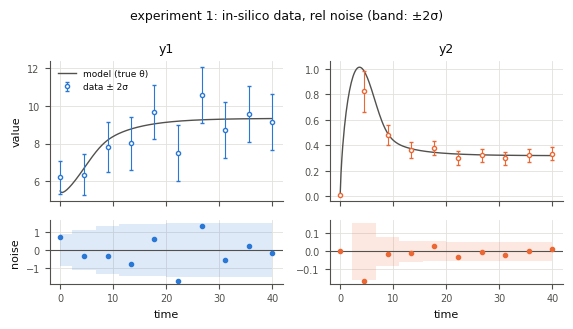

[INFO] Data preview       : tests\tutorials\01_simple\a_relative_fisher_fast\data_plots\experiment_1.png
[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈4.26e+01, cond(M)≈1.81e+03, λ_min(M)≈5.91e+00; OK


CI: [0.06952392 0.12259798 0.26796306 0.04721321]
[INFO] Reading from data.xlsx


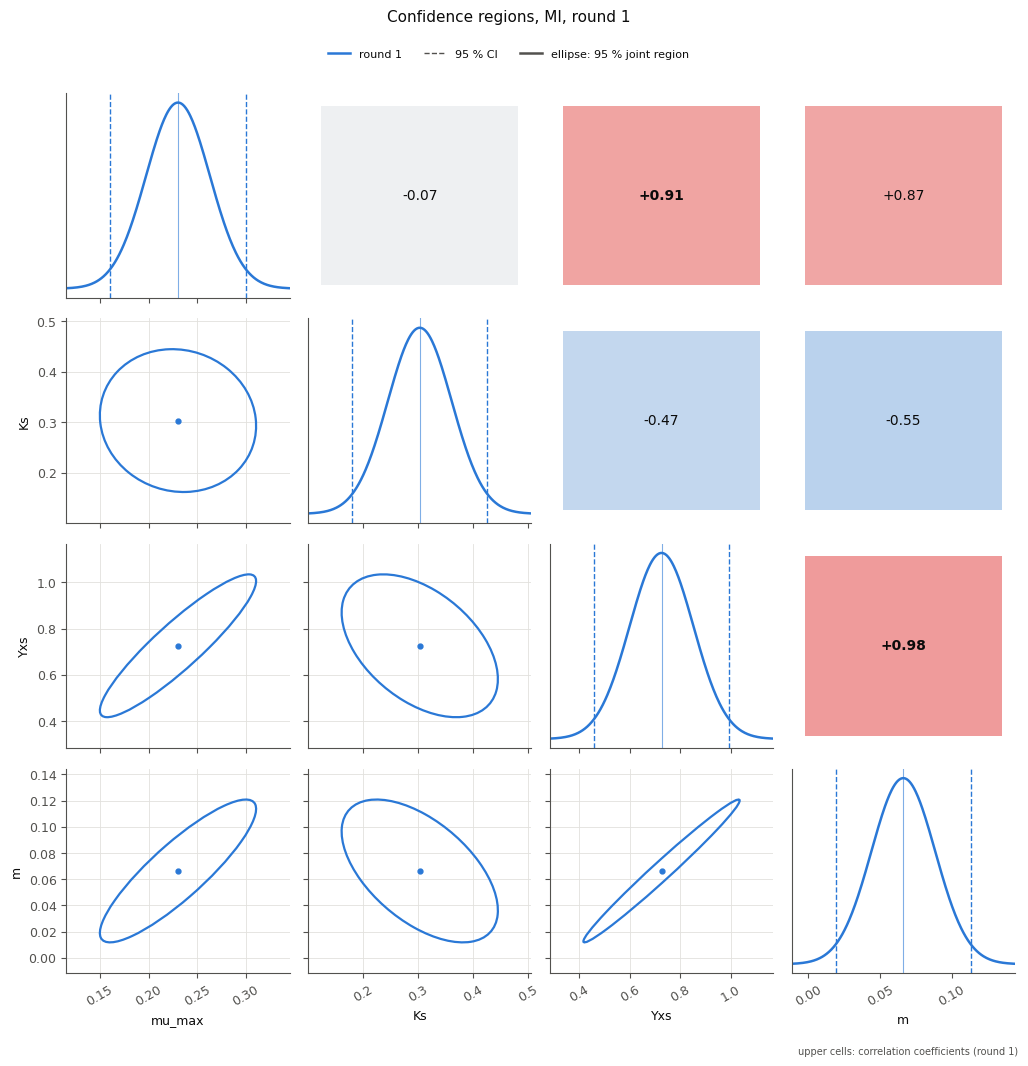

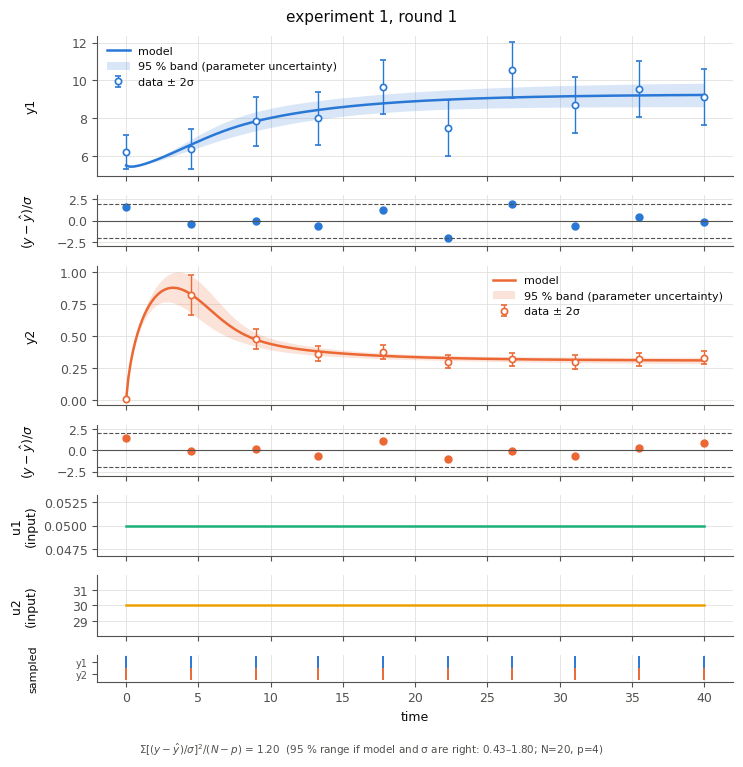

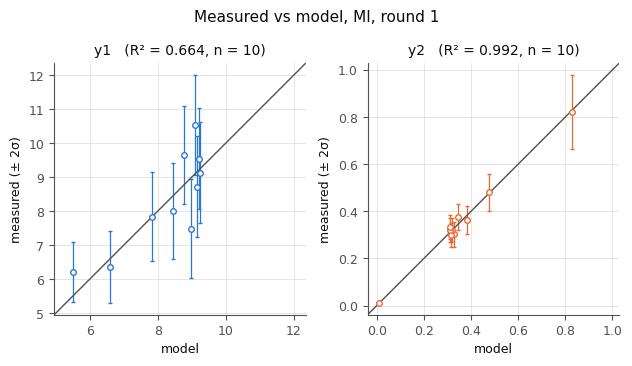

reference t value for model MI and round 1: 2.119905299221011
estimated t values for model MI and round 1: [7.02162296 5.24018073 5.74085445 2.97480005]
P-value for model MI and round 1: 100.0



,estimate,± 95 % CI,t-value,true,estimated
mu_max,0.2303,0.0695,7.0216,0.25,True
Ks,0.3030,0.1226,5.2402,0.25,True
Yxs,0.7257,0.2680,5.7409,0.88,True
m,0.0663,0.0472,2.9748,0.09,True


In [7]:
round = 1
# 1) experiment 1: simulate the true model with insilicos['prels']['1'], add noise, append sheet '1'
#    to data.xlsx, and show the data with its noise. The seed fixes the noise of this experiment, so
#    the variants A-D get identical data (multi-start also draws random numbers in between).
np.random.seed(round)
expera(system, models, insilicos, {}, expr=round)

# 2) estimate from every sheet of data.xlsx. case='strov' starts from the first guess every round;
#    case=None would start from the previous round's estimate (models['theta'])
resultpr = parmest(system, models, iden_opt, case='strov')

# 3) uncertainty: covariance V, 95 % CI, t-values; stores the estimates and V in models
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun, obs = uncert_results['results'], uncert_results['obs']

# 4) store the round: prints the t-test and draws data vs model (with error bars, 95 % band,
#    weighted residuals), the parity plot and the 95 % confidence regions
save_rounds(round, resultun, 'preliminary', round_data, models, iden_opt, obs, system)
show_round(resultun)

## Round 2
Run experiment 2 in silico, then estimate from all data so far. Experiments 1–2 are now in `data.xlsx`; the fit uses all of them.

[✓] In-silico data saved to: tests\tutorials\01_simple\a_relative_fisher_fast\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


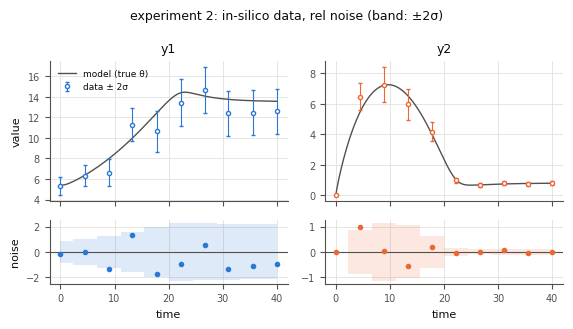

[INFO] Data preview       : tests\tutorials\01_simple\a_relative_fisher_fast\data_plots\experiment_2.png
[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈9.75e+01, cond(M)≈9.51e+03, λ_min(M)≈3.51e+01; OK


CI: [0.02481188 0.03375663 0.11187317 0.02399742]
[INFO] Reading from data.xlsx


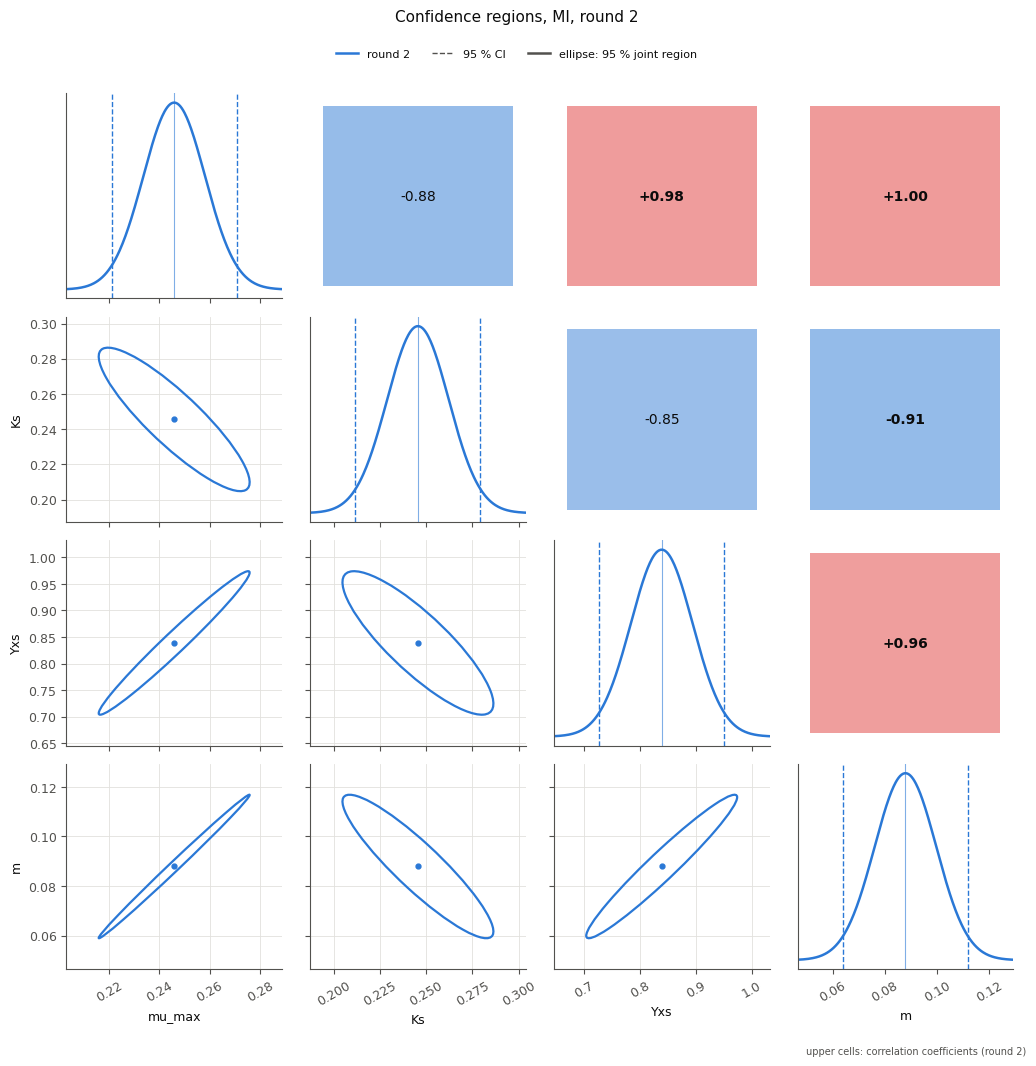

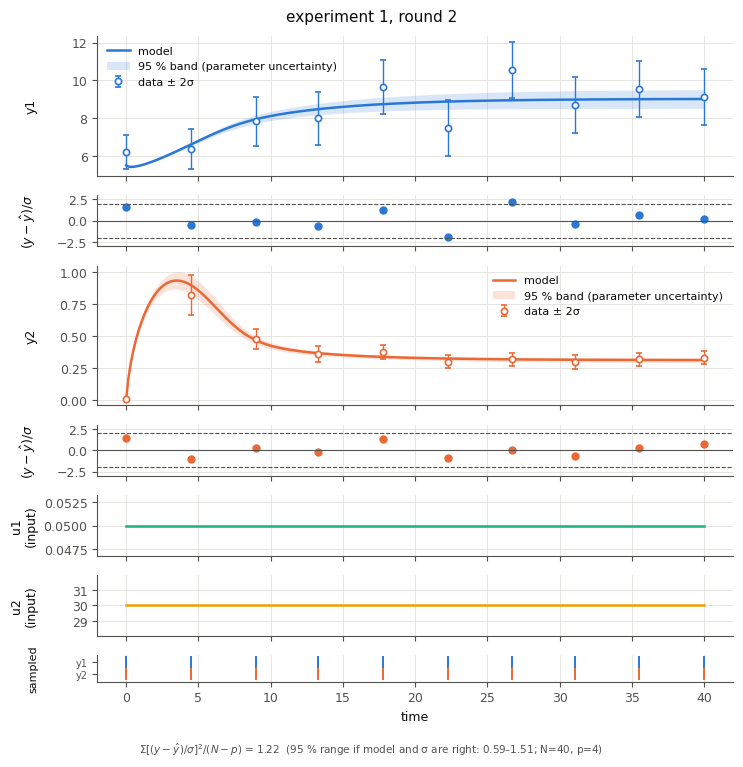

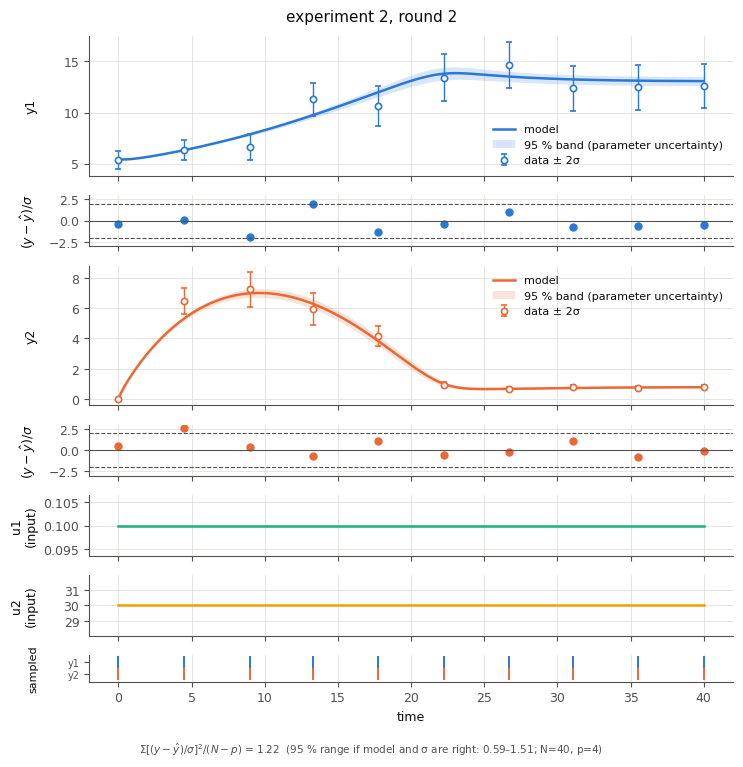

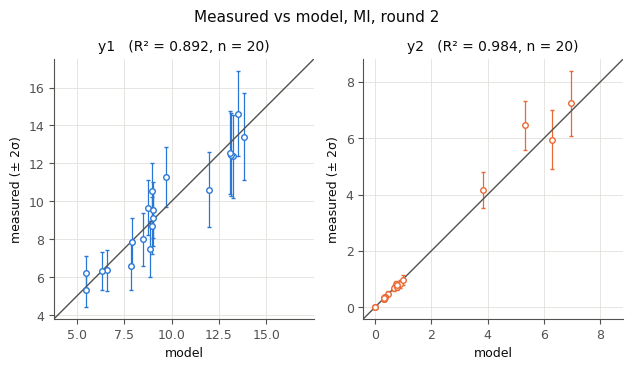

reference t value for model MI and round 2: 2.0280940009804502
estimated t values for model MI and round 2: [20.09977773 14.75272369 15.20830913  7.42690674]
P-value for model MI and round 2: 100.0



,estimate,± 95 % CI,t-value,true,estimated
mu_max,0.2459,0.0248,20.0998,0.25,True
Ks,0.2456,0.0338,14.7527,0.25,True
Yxs,0.8389,0.1119,15.2083,0.88,True
m,0.0879,0.0240,7.4269,0.09,True


In [8]:
round = 2
# 1) experiment 2: simulate the true model with insilicos['prels']['2'], add noise, append sheet '2'
#    to data.xlsx, and show the data with its noise. The seed fixes the noise of this experiment, so
#    the variants A-D get identical data (multi-start also draws random numbers in between).
np.random.seed(round)
expera(system, models, insilicos, {}, expr=round)

# 2) estimate from every sheet of data.xlsx. case='strov' starts from the first guess every round;
#    case=None would start from the previous round's estimate (models['theta'])
resultpr = parmest(system, models, iden_opt, case='strov')

# 3) uncertainty: covariance V, 95 % CI, t-values; stores the estimates and V in models
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun, obs = uncert_results['results'], uncert_results['obs']

# 4) store the round: prints the t-test and draws data vs model (with error bars, 95 % band,
#    weighted residuals), the parity plot and the 95 % confidence regions
save_rounds(round, resultun, 'preliminary', round_data, models, iden_opt, obs, system)
show_round(resultun)

## Round 3
Run experiment 3 in silico, then estimate from all data so far. Experiments 1–3 are now in `data.xlsx`; the fit uses all of them.

[✓] In-silico data saved to: tests\tutorials\01_simple\a_relative_fisher_fast\data.xlsx
[INFO] Model used         : MI
[INFO] Design case        : classic/preliminary
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.08
   - y2         | measurable      | std.dev = 0.08


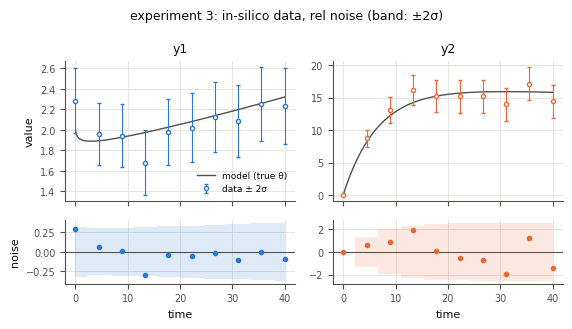

[INFO] Data preview       : tests\tutorials\01_simple\a_relative_fisher_fast\data_plots\experiment_3.png
[INFO] Reading from data.xlsx


[INFO] Reading from data.xlsx
active_idx: [0 1 2 3]


INFO:middoe.iden_uncert:Conditioning diagnostics: (scaled) Rank(Q)=4/4, cond(Q)≈1.01e+02, cond(M)≈1.02e+04, λ_min(M)≈3.78e+01; OK


CI: [0.02356719 0.03321474 0.10373454 0.02320489]
[INFO] Reading from data.xlsx


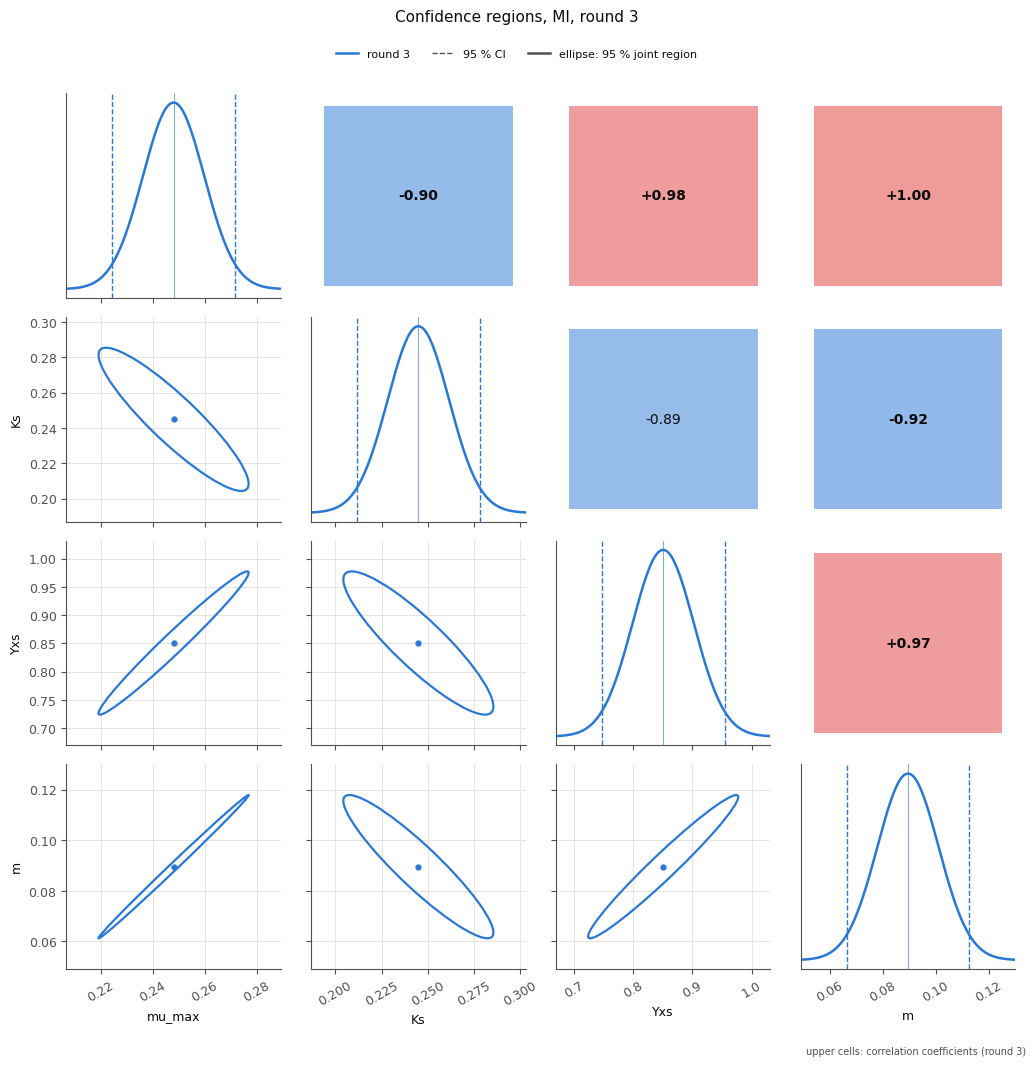

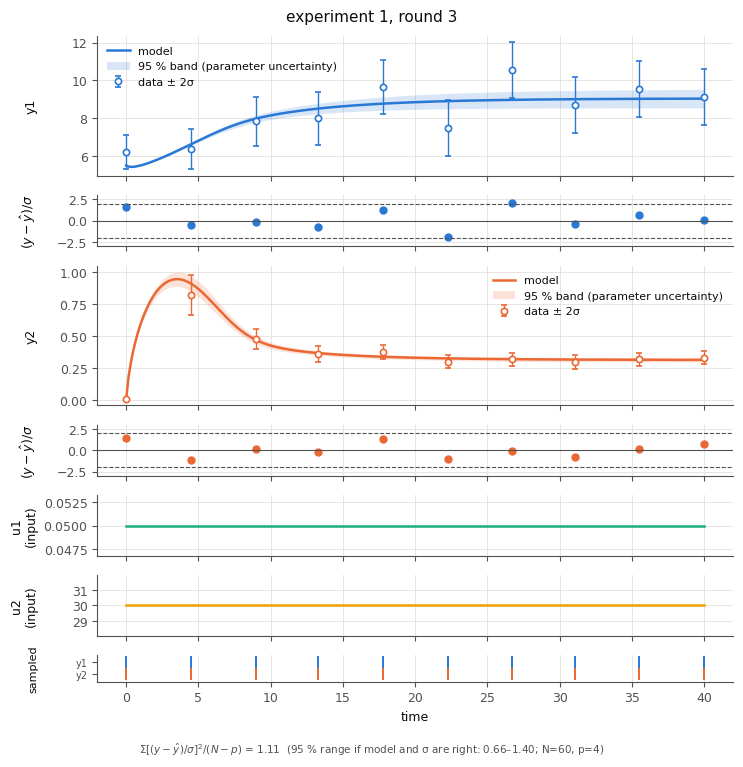

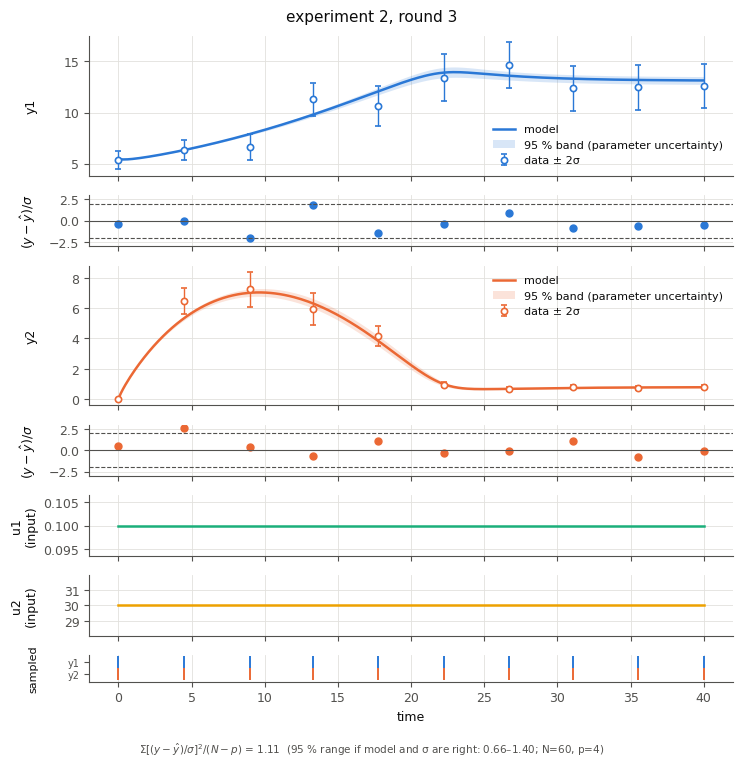

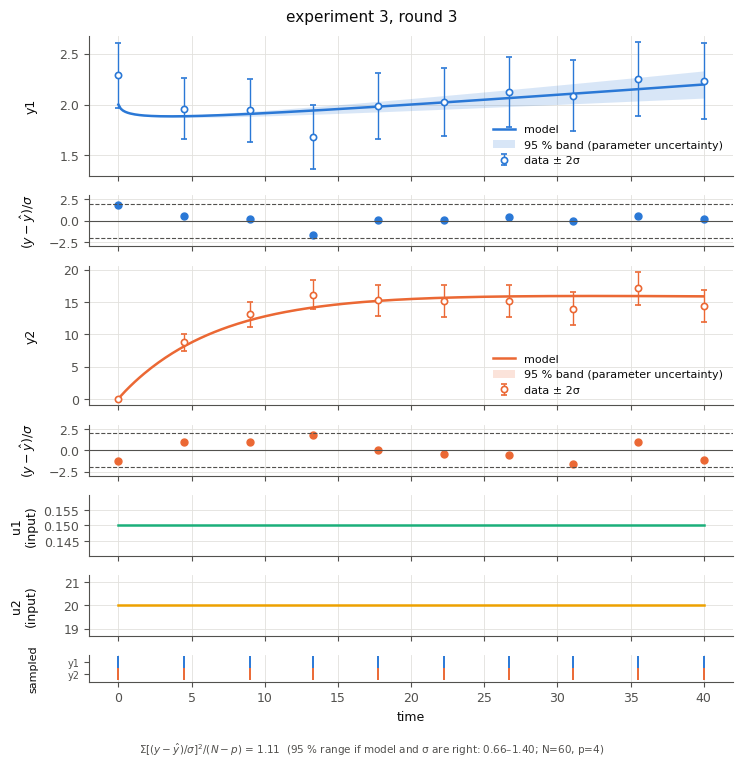

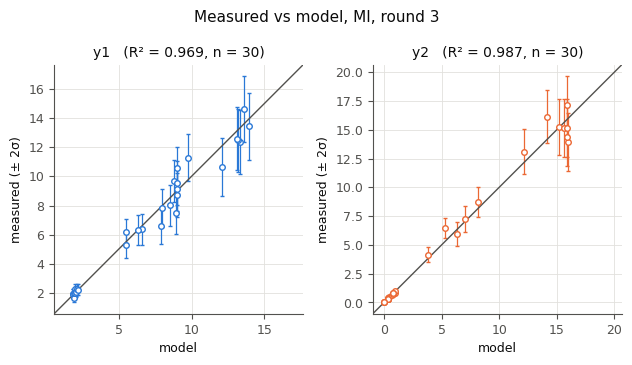

reference t value for model MI and round 3: 2.003240718847872
estimated t values for model MI and round 3: [21.08299038 14.7705028  16.430317    7.73132886]
P-value for model MI and round 3: 100.0



,estimate,± 95 % CI,t-value,true,estimated
mu_max,0.2480,0.0236,21.0830,0.25,True
Ks,0.2449,0.0332,14.7705,0.25,True
Yxs,0.8508,0.1037,16.4303,0.88,True
m,0.0896,0.0232,7.7313,0.09,True


In [9]:
round = 3
# 1) experiment 3: simulate the true model with insilicos['prels']['3'], add noise, append sheet '3'
#    to data.xlsx, and show the data with its noise. The seed fixes the noise of this experiment, so
#    the variants A-D get identical data (multi-start also draws random numbers in between).
np.random.seed(round)
expera(system, models, insilicos, {}, expr=round)

# 2) estimate from every sheet of data.xlsx. case='strov' starts from the first guess every round;
#    case=None would start from the previous round's estimate (models['theta'])
resultpr = parmest(system, models, iden_opt, case='strov')

# 3) uncertainty: covariance V, 95 % CI, t-values; stores the estimates and V in models
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun, obs = uncert_results['results'], uncert_results['obs']

# 4) store the round: prints the t-test and draws data vs model (with error bars, 95 % band,
#    weighted residuals), the parity plot and the 95 % confidence regions
save_rounds(round, resultun, 'preliminary', round_data, models, iden_opt, obs, system)
show_round(resultun)

## Final report
`save_to_jac` keeps every round in `iden_results.jac` (reload it later without rerunning anything).
`run_postprocessing` writes `post_processing/`: confidence regions of all rounds, estimates ± CI per
round (with the true values), relative precision, t-tests, Excel reports per round and a summary.

[INFO] Results saved to: tests\tutorials\01_simple\a_relative_fisher_fast\iden_results.jac
Loaded: iden_results.jac
File not found: sensa_results.jac
P-value plots skipped: only one model, so its probability is always 100 %.


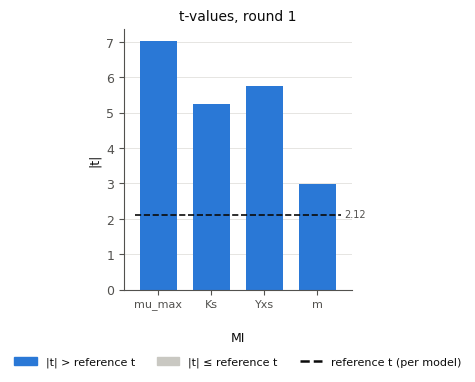

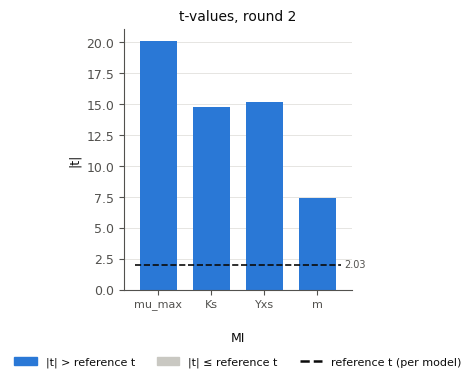

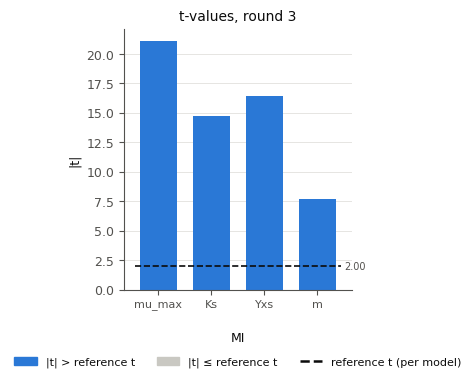

Post-processing model: MI


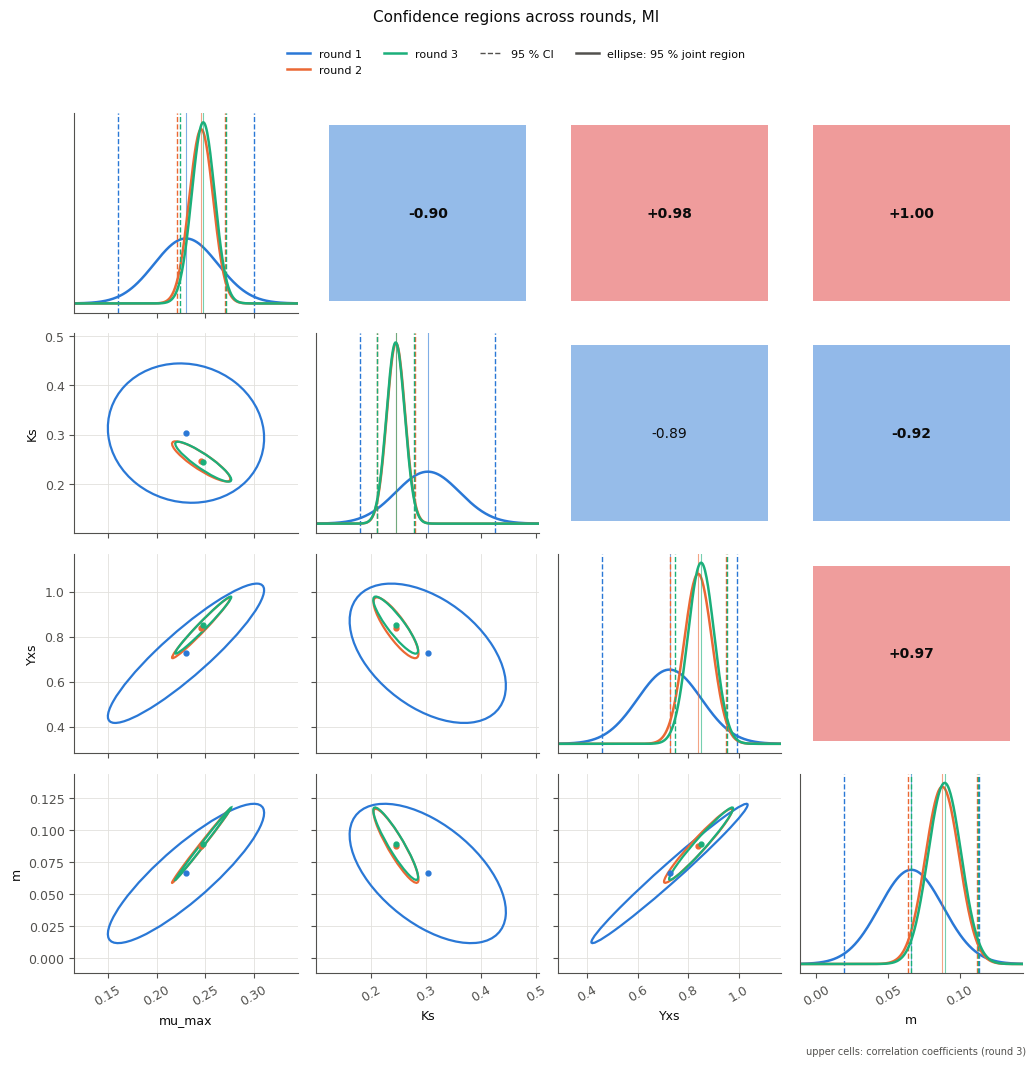

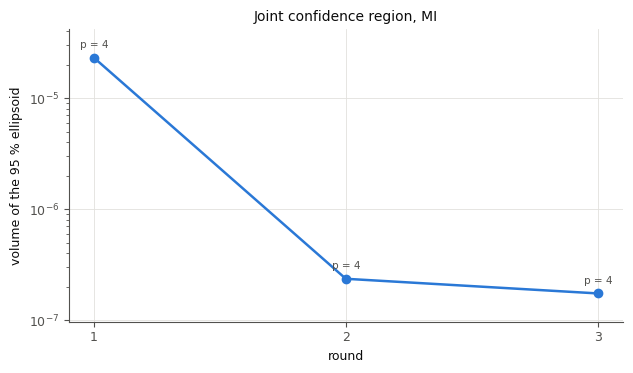

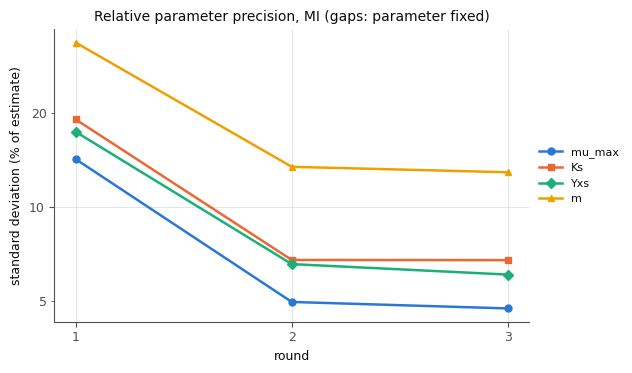

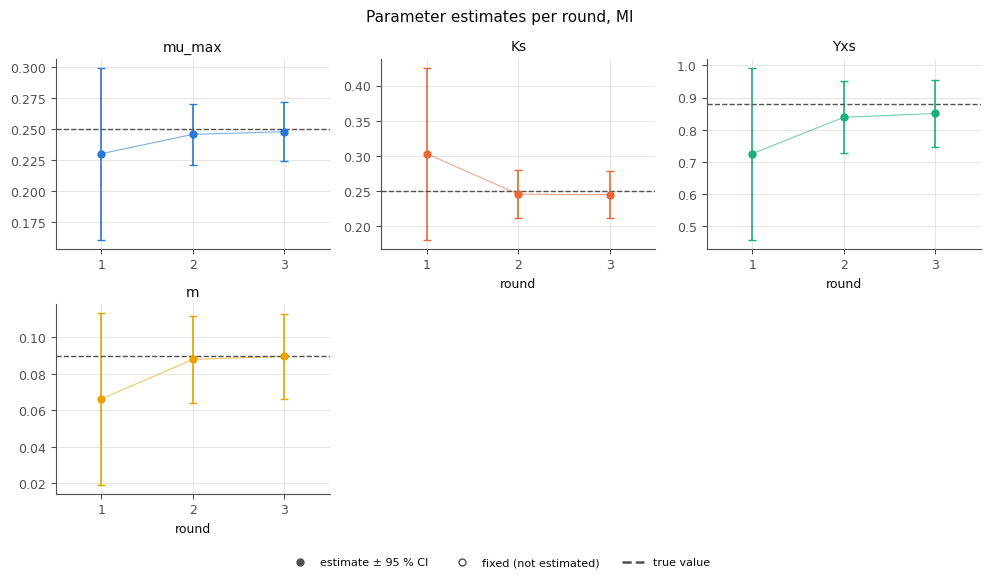

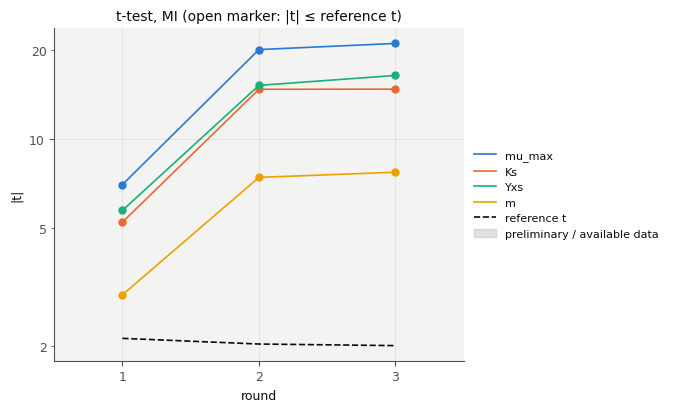

INFO:middoe.iden_utils:Reporter wrote Round 1 to 'tests\tutorials\01_simple\a_relative_fisher_fast\post_processing\MI_report_1.xlsx'.


INFO:middoe.iden_utils:Reporter wrote Round 2 to 'tests\tutorials\01_simple\a_relative_fisher_fast\post_processing\MI_report_2.xlsx'.


INFO:middoe.iden_utils:Reporter wrote Round 3 to 'tests\tutorials\01_simple\a_relative_fisher_fast\post_processing\MI_report_3.xlsx'.


INFO:middoe.iden_utils:Summary written to 'tests\tutorials\01_simple\a_relative_fisher_fast\post_processing\MI_report_summary.txt'.


Post-processing completed for: MI
Round 3  (design: preliminary)

Model: MI
                   parameter      estimate estimated       sd  CI95 (±)  CI95 (% of estimate)         t    t_ref significant
                      mu_max      0.248031      True 0.011765  0.023567              9.501692 21.082990 2.003241        True
                          Ks      0.244902      True 0.016581  0.033215             13.562441 14.770503 2.003241        True
                         Yxs      0.850817      True 0.051783  0.103735             12.192344 16.430317 2.003241        True
                           m      0.089557      True 0.011584  0.023205             25.910691  7.731329 2.003241        True
                                                                                                                            
            N (measurements)            60                                                                                  
    p (estimated parameters)             4       

In [10]:
save_to_jac(round_data, purpose='iden')
round_data = load_from_jac()['iden']

run_postprocessing(round_data, ['MI'], [1, 2, 3],
                   plot_global_p_and_t=True,      # t-values per round (P only with several models)
                   plot_confidence_spaces=True,   # regions, estimates ± CI, precision, volume
                   plot_p_and_t_tests=True,       # t-test over the rounds
                   export_excel_reports=True,     # MI_report_k.xlsx + MI_report_summary.txt
                   plot_estimability=False,       # rCC vs k (needs estima, as in variant C)
                   true_theta={'MI': theta},      # true values on the estimate plot (in silico only)
                   show=True)
print(open('post_processing/MI_report_summary.txt', encoding='utf-8').read())